# ДЗ 1. Рекомендации на Amazon Reviews 2023 (Video Games)

**Михайлов Владислав Вадимович**

Задача: по истории покупок пользователя на Amazon в категории Video Games порекомендовать ему 10 товаров (игры,
консоли, аксессуары), которые он потом купит и оценит хорошо.

**Запуск.** Ставим пакеты из `requirements.txt` (я запускал на Python 3.12), открываем ноутбук в Jupyter или VS Code и
жмём Run All. Первая ячейка сама скачает данные (~480 МБ) в `data/`, если их там ещё нет:
* оценки (5-core): https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/benchmark/5core/rating_only/Video_Games.csv
* метаданные: https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/raw/meta_categories/meta_Video_Games.jsonl

Сид везде 42, параметры фильтрации и разбиения — константы в `models/utils.py`. На моём MacBook (CPU) всё считается
примерно час, больше всего времени уходит на перебор гиперпараметров.


In [1]:
import time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, optuna, torch
from models import utils as U
from models import ItemKNN, IALS, EASE, FM, IALSCustomTarget, Popular, RecentPopular, Stage

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
torch.set_num_threads(8)
U.set_seed(U.SEED)
pd.set_option("display.precision", 4); pd.set_option("display.max_colwidth", None)
_ = U.download_data()

## 1. Данные

**Датасет:** Amazon Reviews 2023, категория *Video_Games* (McAuley Lab, UCSD; Hou et al., *Bridging Language and Items
for Retrieval and Recommendation*, 2024). Первоисточник: https://amazon-reviews-2023.github.io/ ,
файлы на Hugging Face: https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023 .
Берём официальную 5-core версию рейтингов (каждый пользователь и товар имеют ≥ 5 отзывов) и сырые метаданные товаров.

Поля взаимодействий: `user_id` — анонимный ID пользователя, `parent_asin` — ID товара (объединяет вариации товара),
`rating` — оценка 1–5 из отзыва, `timestamp` — время отзыва (мс, Unix). Взаимодействие = пользователь купил товар и
оставил отзыв с оценкой.

Метаданные товара: `title`, `main_category`, `store` (издатель/бренд), `categories` (иерархия Amazon: платформа, тип
товара), `price`, `details` (ESRB-рейтинг, дата появления и т.д.).

**Что рекомендуем:** товары категории Video Games, которых ещё нет в истории пользователя.
**Релевантный объект:** товар, который пользователь купил в отложенном периоде и оценил на **≥ 4**. Покупка с низкой
оценкой — неудачная рекомендация, поэтому в релевантные она не входит.

In [2]:
ratings, meta = U.load_raw()
ratings["dt"] = pd.to_datetime(ratings["timestamp"], unit="ms")
print("Исходно (5-core):", f"{len(ratings):,} взаимодействий, {ratings.user_id.nunique():,} пользователей, "
      f"{ratings.parent_asin.nunique():,} товаров; метаданные найдены для {len(meta):,} товаров")
ratings.head()

Исходно (5-core): 814,586 взаимодействий, 94,762 пользователей, 25,612 товаров; метаданные найдены для 25,612 товаров


,user_id,parent_asin,rating,timestamp,dt
0,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B08R5B7YS4,1.0,1611459666223,2021-01-24 03:41:06.223
1,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B0863MT183,4.0,1613701986538,2021-02-19 02:33:06.538
2,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B08P8P7686,5.0,1613702112995,2021-02-19 02:35:12.995
3,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B0B7LV3DN2,4.0,1617641445475,2021-04-05 16:50:45.475
4,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B09WMQ6DXG,5.0,1620231368468,2021-05-05 16:16:08.468


## 2. EDA и подготовка данных
### 2.1 Пропуски, дубликаты, оценки, время

Пропуски в рейтингах:
 {'user_id': 0, 'parent_asin': 0, 'rating': 0, 'timestamp': 0, 'dt': 0}
Дубликаты (user, item): 0
Полные дубликаты строк: 0
Период: 1999-10-22 21:43:15 — 2023-09-02 18:14:28.630000


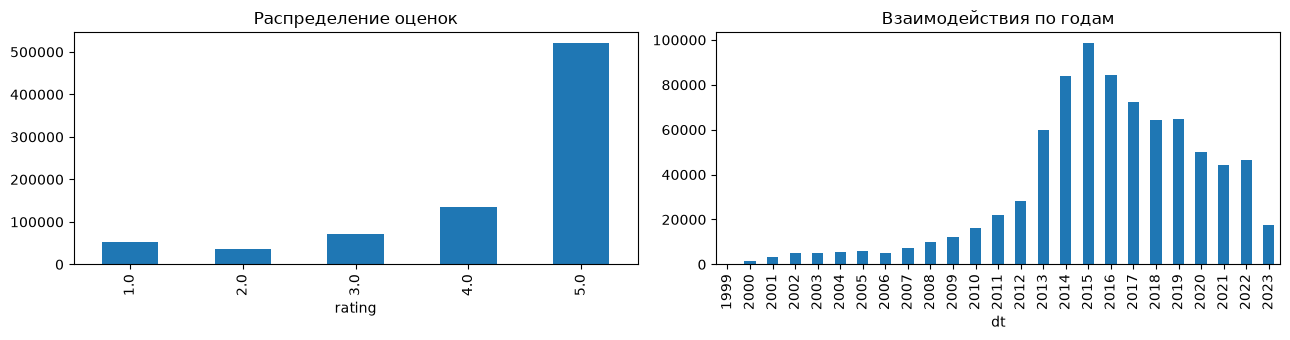

{1.0: 0.065, 2.0: 0.045, 3.0: 0.086, 4.0: 0.165, 5.0: 0.638}


In [3]:
print("Пропуски в рейтингах:\n", ratings.isna().sum().to_dict())
print("Дубликаты (user, item):", ratings.duplicated(["user_id", "parent_asin"]).sum())
print("Полные дубликаты строк:", ratings.duplicated().sum())
print("Период:", ratings.dt.min(), "—", ratings.dt.max())

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ratings.rating.value_counts().sort_index().plot.bar(ax=ax[0], title="Распределение оценок")
ratings.dt.dt.year.value_counts().sort_index().plot.bar(ax=ax[1], title="Взаимодействия по годам")
plt.tight_layout(); plt.show()
print(ratings.rating.value_counts(normalize=True).sort_index().round(3).to_dict())

Пропусков и дубликатов пар (user, item) нет. Оценки сильно смещены вверх (64 % пятёрок), поэтому порог
релевантности ≥ 4 оставляет ~80 % взаимодействий, а оценки 1–3 несут информацию о неудачных покупках.
Данные до 2012 года очень редкие, пик активности 2014–2016, затем плавное снижение; последний год (2023) неполный.

### 2.2 Активность пользователей, популярность товаров, разреженность

исходные: 814,586 взаимодействий, 94,762 пользователей, 25,612 товаров, плотность 0.03356%
Активность пользователей: {'count': 94762.0, 'mean': 8.6, 'std': 7.9, 'min': 5.0, '25%': 5.0, '50%': 6.0, '75%': 9.0, 'max': 473.0}
Популярность товаров: {'count': 25612.0, 'mean': 31.8, 'std': 78.0, 'min': 5.0, '25%': 7.0, '50%': 12.0, '75%': 26.0, 'max': 2955.0}
Топ-10% товаров дают 56.1% взаимодействий


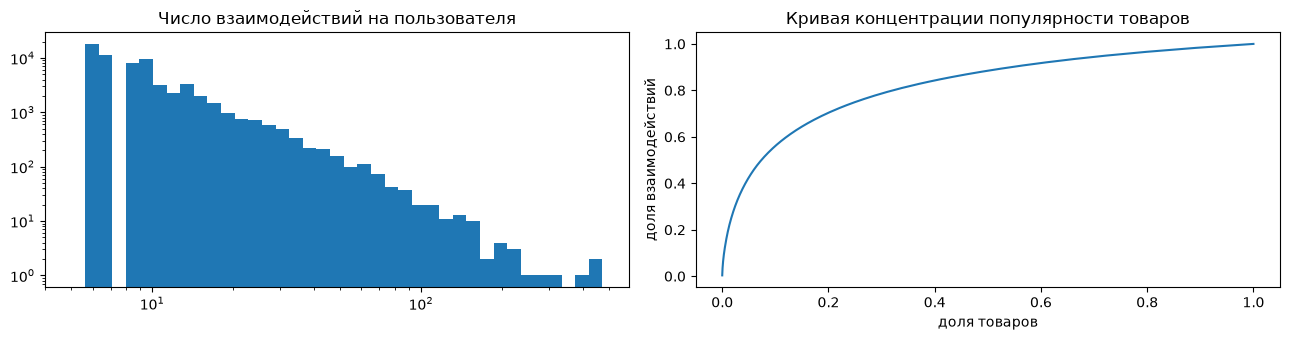

In [4]:
def describe(df, name):
    nu, ni = df.user_id.nunique(), df.parent_asin.nunique()
    print(f"{name}: {len(df):,} взаимодействий, {nu:,} пользователей, {ni:,} товаров, "
          f"плотность {len(df) / nu / ni:.5%}")

describe(ratings, "исходные")
uc, ic = ratings.user_id.value_counts(), ratings.parent_asin.value_counts()
print("Активность пользователей:", uc.describe().round(1).to_dict())
print("Популярность товаров:", ic.describe().round(1).to_dict())
top = ic.sort_values(ascending=False).cumsum() / ic.sum()
print(f"Топ-10% товаров дают {top.iloc[int(len(ic) * 0.1)]:.1%} взаимодействий")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].hist(uc, bins=np.logspace(np.log10(5), np.log10(uc.max()), 40)); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_title("Число взаимодействий на пользователя")
ax[1].plot(np.arange(len(ic)) / len(ic), top.values); ax[1].set_title("Кривая концентрации популярности товаров")
ax[1].set_xlabel("доля товаров"); ax[1].set_ylabel("доля взаимодействий")
plt.tight_layout(); plt.show()

### 2.3 Метаданные

In [5]:
m = meta.copy()
print("Доля пропусков:", {"store": m.store.isna().mean().round(3), "price": m.price.isna().mean().round(3),
      "categories (пусто)": (m.categories.str.len() == 0).mean().round(3), "ESRB": m.rated.isna().mean().round(3),
      "date_first_available": m.date_first_available.isna().mean().round(3)})
print("\nmain_category:", m.main_category.value_counts().head(6).to_dict())
print("\nТоп store:", m.store.value_counts().head(10).to_dict())
cats = pd.Series([c for cs in m.categories for c in cs if c != "Video Games"]).value_counts()
print(f"\nУникальных категорий: {len(cats)}; топ:", cats.head(15).to_dict())
print("\nESRB:", m.rated.value_counts().head(6).to_dict())

Доля пропусков: {'store': np.float64(0.005), 'price': np.float64(0.331), 'categories (пусто)': np.float64(0.034), 'ESRB': np.float64(0.524), 'date_first_available': np.float64(0.042)}

main_category: {'Video Games': 17930, 'Computers': 3263, 'All Electronics': 2645, 'Cell Phones & Accessories': 414, 'Toys & Games': 217, 'Software': 204}

Топ store: {'Nintendo': 1499, 'Electronic Arts': 943, 'Ubisoft': 627, 'ACTIVISION': 620, 'PlayStation': 578, 'Microsoft': 576, 'SEGA': 482, 'Sony': 476, 'Square Enix': 381, 'BANDAI NAMCO Entertainment': 364}

Уникальных категорий: 160; топ: {'Legacy Systems': 11708, 'Games': 11450, 'Accessories': 10325, 'PC': 6355, 'Nintendo Systems': 5270, 'PlayStation Systems': 3759, 'Nintendo Switch': 2268, 'Xbox Systems': 2077, 'PlayStation 4': 1824, 'Controllers': 1741, 'Headsets': 1450, 'Xbox One': 1446, 'Xbox 360': 1375, 'Wii': 1241, 'PlayStation 3': 1189}

ESRB: {'Everyone': 4190, 'Teen': 3329, 'Mature': 2163, 'Everyone 10+': 1303, 'Rating Pending': 1045, 'Kids

Метаданные заполнены хорошо: store (издатель/бренд) почти у всех товаров, иерархия категорий у ~97 %
(платформа: PlayStation/Xbox/Nintendo/PC; тип: игра, аксессуар, контроллер, гарнитура…), ESRB-рейтинг у ~половины.
Для FM берём **store, main_category, categories, ESRB, год появления товара** — статические атрибуты, известные на момент
рекомендации, плюс **популярность товара**, посчитанную только по обучающему периоду. **Не берём** `price`,
`average_rating`, `rating_number`: это снимок страницы 2023 года, т.е. информация из будущего относительно
validation/test (утечка). Пользовательских метаданных в датасете нет, поэтому профиль пользователя строим из
метапризнаков товаров его прошлой истории (доля платформ, жанров, издателей).

### 2.4 Очистка и подвыборка
1. **Временное окно с 2015-01-01.** Ранние годы редкие и описывают другое поколение платформ; окно делает данные
   однороднее и уменьшает каталог (нужен для EASE и ItemKNN с плотной матрицей item×item).
2. **Итеративный k-core:** товар ≥ 10 взаимодействий, пользователь ≥ 5 (повторяем, пока что-то удаляется).
   Товары с < 10 отзывами почти не дают сигнала для коллаборативных моделей.

Отбор детерминированный (без случайного сэмплирования), поэтому полностью воспроизводим.

In [6]:
data = U.filter_interactions(ratings)
data, users, items = U.encode(data)
describe(data, "итоговая выборка")
assert 100_000 <= len(data) <= 2_000_000 and len(users) >= 1000 and len(items) >= 1000
print("Активность пользователей:", data.groupby("uid").size().describe().round(1).to_dict())
print("Популярность товаров:", data.groupby("iid").size().describe().round(1).to_dict())

итоговая выборка: 345,731 взаимодействий, 43,856 пользователей, 8,175 товаров, плотность 0.09643%
Активность пользователей: {'count': 43856.0, 'mean': 7.9, 'std': 5.9, 'min': 5.0, '25%': 5.0, '50%': 6.0, '75%': 8.0, 'max': 382.0}
Популярность товаров: {'count': 8175.0, 'mean': 42.3, 'std': 76.4, 'min': 10.0, '25%': 13.0, '50%': 21.0, '75%': 40.0, 'max': 2288.0}


## 3. Протокол оценки

* **Глобальное временное разбиение** (одна граница времени для всех пользователей — нет утечки будущего):
  train: 2015-01 … 2020-12, validation: 2021, test: 2022-01 … 2023-09.
* **Подбор гиперпараметров:** обучение на train, оценка на validation.
  **Финал:** переобучение с выбранными гиперпараметрами на train+validation, оценка на test (test используется один раз).
* **Пользователи для оценки:** «тёплые» — есть хотя бы одно взаимодействие в периоде обучения и хотя бы один
  релевантный (оценка ≥ 4) новый товар в оцениваемом периоде. Новые пользователи (без истории) персонально
  не оцениваются — для них в продакшене была бы популярность; их доля приведена ниже.
* **Кандидаты:** все товары, встречавшиеся в периоде обучения. Новые товары (впервые появились в оцениваемом
  периоде) рекомендовать нельзя ни одной модели, но они **остаются в знаменателе Recall** — честная оценка.
* **Исключение известного:** товары из истории пользователя (за период обучения) удаляются из выдачи и из
  множества релевантных.
* Критерий релевантности одинаков для всех моделей и не зависит от обучающего таргета модели.

**Основная метрика (выбрана до подбора): NDCG@10** — учитывает и попадание, и позицию релевантного товара в
коротком списке, что соответствует витрине из 10 позиций. Дополнительно: **Recall@10** (какую долю будущих
понравившихся покупок мы покрываем), **HitRate@10** (доля пользователей с хотя бы одним попаданием — «полезность»
выдачи для пользователя), MRR@10 и **Coverage@10** (доля каталога, попавшая в чьи-то рекомендации — разнообразие).

In [7]:
train, val, test = U.temporal_split(data)
trainval = pd.concat([train, val])
for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:>10}: {len(part):,} взаимодействий, {part.uid.nunique():,} пользователей, {part.iid.nunique():,} товаров")

val_stage = Stage(train, val, len(users), len(items), meta, items)
test_stage = Stage(trainval, test, len(users), len(items), meta, items)
for name, st, ev in [("validation", val_stage, val), ("test", test_stage, test)]:
    fit_users, fit_items = set(st.fit_df.uid), set(st.fit_df.iid)
    pos = ev[ev.rating >= U.RELEVANT_RATING]
    print(f"\n[{name}] пользователей для оценки: {len(st.users):,}; кандидатов: {st.candidates.sum():,}")
    print(f"  доля новых пользователей среди активных в периоде: {1 - ev.uid.isin(fit_users).mean():.1%} взаимодействий, "
          f"{1 - np.mean([u in fit_users for u in ev.uid.unique()]):.1%} пользователей")
    print(f"  релевантных взаимодействий с новыми товарами (недостижимы): {(~pos.iid.isin(fit_items)).mean():.1%}")
    print(f"  в среднем релевантных товаров на пользователя: {np.mean([len(v) for v in st.rel.values()]):.2f}")
print("\nПризнаков товара (без ID):", val_stage.item_features.shape[1])

     train: 291,324 взаимодействий, 41,518 пользователей, 7,378 товаров
validation: 26,104 взаимодействий, 11,121 пользователей, 4,560 товаров
      test: 28,303 взаимодействий, 10,551 пользователей, 4,229 товаров



[validation] пользователей для оценки: 7,904; кандидатов: 7,378
  доля новых пользователей среди активных в периоде: 23.4% взаимодействий, 12.3% пользователей
  релевантных взаимодействий с новыми товарами (недостижимы): 18.7%
  в среднем релевантных товаров на пользователя: 1.97

[test] пользователей для оценки: 7,775; кандидатов: 7,811
  доля новых пользователей среди активных в периоде: 23.6% взаимодействий, 9.2% пользователей
  релевантных взаимодействий с новыми товарами (недостижимы): 24.7%
  в среднем релевантных товаров на пользователя: 2.15

Признаков товара (без ID): 507


## 4. Модели и подбор гиперпараметров

Все модели реализованы с нуля в `models/` (NumPy/SciPy, PyTorch для батчевых решений и autograd) и имеют
общий интерфейс `fit(stage)` / `score(users)`; формирование top-10 с исключениями — общее (`utils.recommend`).

**Бейзлайны** (для ориентира): популярность за весь период обучения и популярность за последние $D$ дней
периода обучения ($D \in \{30, 90, 180, 365\}$ подбирается на validation).

In [8]:
def run(model, stage):
    t = time.time(); model.fit(stage); res, recs = stage.run(model)
    res["time, s"] = round(time.time() - t, 1)
    return res, recs

def grid_search(make, grid, stage=val_stage):
    rows = []
    for params in grid:
        res, _ = run(make(**params), stage)
        rows.append({**params, **res})
    return pd.DataFrame(rows).sort_values("NDCG@10", ascending=False).reset_index(drop=True)

from itertools import product
def grid(**kw):
    return [dict(zip(kw, v)) for v in product(*kw.values())]

best = {}
val_results = {}
pop_res, _ = run(Popular(), val_stage); val_results["Popular"] = pop_res
recent_grid = grid_search(RecentPopular, grid(days=[30, 90, 180, 365]))
best["RecentPopular"] = {"days": int(recent_grid.iloc[0]["days"])}
recent_grid

,days,NDCG@10,Recall@10,HitRate@10,MRR@10,Coverage@10,"time, s"
0,180,0.0219,0.0405,0.0733,0.0221,0.0023,0.4
1,30,0.0218,0.0400,0.0719,0.0215,0.0023,0.4
2,90,0.0215,0.0386,0.0705,0.0214,0.0023,0.4
3,365,0.0181,0.0343,0.0649,0.0188,0.0027,0.3


### 4.1 ItemKNN (item-based CF)
Бинарная матрица $X \in \{0,1\}^{|U|\times|I|}$. Сходство — косинус со сжатием:
$$s_{ij} = \frac{x_i^\top x_j}{\|x_i\|\,\|x_j\| + \text{shrink}},$$
для каждого товара оставляем $k$ ближайших соседей. Скор: $\hat r_{uj} = \sum_{i \in I(u)} s_{ij}$.
Опция `idf` понижает вес очень активных пользователей ($x_{ui}/\log(2 + |I(u)|)$).
Пространство поиска: $k \in \{20, 50, 100, 200, 500, 1000\}$, shrink $\in \{0, 10, 50, 200, 500\}$, idf $\in$ {нет, да}.

In [9]:
knn_grid = grid_search(ItemKNN, grid(k=[20, 50, 100, 200, 500, 1000], shrink=[0.0, 10.0, 50.0, 200.0, 500.0], idf=[False, True]))
best["ItemKNN"] = knn_grid.iloc[0][["k", "shrink", "idf"]].to_dict(); best["ItemKNN"]["k"] = int(best["ItemKNN"]["k"])
knn_grid.head(8)

,k,shrink,idf,NDCG@10,Recall@10,HitRate@10,MRR@10,Coverage@10,"time, s"
0,1000,500.0,True,0.0142,0.0237,0.0453,0.0167,0.4707,1.4
1,1000,500.0,False,0.0141,0.0230,0.0447,0.0170,0.5386,1.4
2,1000,200.0,True,0.0141,0.0239,0.0452,0.0163,0.4862,1.5
3,500,500.0,True,0.0139,0.0237,0.0447,0.0160,0.4928,1.5
4,1000,200.0,False,0.0138,0.0225,0.0435,0.0165,0.5743,1.5
5,500,200.0,True,0.0138,0.0237,0.0444,0.0157,0.5064,1.5
6,1000,50.0,True,0.0138,0.0233,0.0444,0.0159,0.5562,1.5
7,500,500.0,False,0.0138,0.0227,0.0436,0.0164,0.5645,1.5


### 4.2 iALS (неявная обратная связь)
Hu, Koren, Volinsky (2008). Предпочтение $p_{ui} = [\text{было взаимодействие}]$, уверенность $c_{ui} = 1 + \alpha p_{ui}$:
$$\min_{X,Y} \sum_{u,i} c_{ui}\,(p_{ui} - x_u^\top y_i)^2 + \lambda\Big(\sum_u \|x_u\|^2 + \sum_i \|y_i\|^2\Big).$$
Попеременные точные шаги: $x_u = (Y^\top Y + Y^\top (C^u - I) Y + \lambda I)^{-1} Y^\top C^u p_u$ (аналогично для $y_i$),
$Y^\top Y$ считается один раз за шаг. Выбор неявной постановки: в задаче важен сам факт будущей покупки, а не
предсказание оценки. Число итераций фиксировано: 15.
Пространство: factors $\in \{32, 64, 128\}$, $\lambda \in \{1, 10, 50, 200, 500\}$, $\alpha \in \{1, 5, 20, 50, 100\}$.

In [10]:
ials_grid = grid_search(IALS, grid(factors=[32, 64, 128], reg=[1.0, 10.0, 50.0, 200.0, 500.0], alpha=[1.0, 5.0, 20.0, 50.0, 100.0]))
best["iALS"] = ials_grid.iloc[0][["factors", "reg", "alpha"]].to_dict(); best["iALS"]["factors"] = int(best["iALS"]["factors"])
ials_grid.head(8)

,factors,reg,alpha,NDCG@10,Recall@10,HitRate@10,MRR@10,Coverage@10,"time, s"
0,128,500.0,100.0,0.0139,0.0230,0.0444,0.0165,0.1948,24.5
1,64,500.0,100.0,0.0136,0.0219,0.0429,0.0161,0.1654,6.4
2,128,200.0,100.0,0.0136,0.0224,0.0435,0.0157,0.3330,22.3
3,128,200.0,50.0,0.0133,0.0215,0.0426,0.0160,0.2425,22.4
4,64,200.0,50.0,0.0133,0.0216,0.0423,0.0157,0.1786,6.5
5,128,50.0,50.0,0.0132,0.0221,0.0420,0.0152,0.3410,30.3
6,128,500.0,50.0,0.0131,0.0208,0.0397,0.0160,0.0656,23.0
7,32,500.0,50.0,0.0130,0.0201,0.0383,0.0160,0.0568,2.9


### 4.3 EASE
Steck (2019): $\min_B \|X - XB\|_F^2 + \lambda\|B\|_F^2$ при $\operatorname{diag}(B)=0$. Замкнутая форма:
$P = (X^\top X + \lambda I)^{-1}$, $B_{ij} = -P_{ij}/P_{jj}$, $B_{jj}=0$. Скор $\hat r_u = x_u B$.
Выбран EASE, а не SLIM: решение аналитическое, без координатного спуска, и каталог из ~8 тыс. товаров позволяет
обратить матрицу item×item. Пространство: $\lambda \in \{10, 50, 100, 250, 500, 1000, 2500, 5000\}$.

In [11]:
ease_grid = grid_search(EASE, grid(reg=[10.0, 50.0, 100.0, 250.0, 500.0, 1000.0, 2500.0, 5000.0]))
best["EASE"] = ease_grid.iloc[0][["reg"]].to_dict()
ease_grid

,reg,NDCG@10,Recall@10,HitRate@10,MRR@10,Coverage@10,"time, s"
0,100.0,0.0146,0.0224,0.0443,0.0182,0.5625,7.5
1,250.0,0.0144,0.0230,0.0447,0.0177,0.5331,7.0
2,50.0,0.0142,0.0215,0.0428,0.0181,0.6060,7.3
3,500.0,0.0141,0.0227,0.0444,0.0173,0.5213,7.2
4,5000.0,0.0141,0.0232,0.0457,0.0169,0.4915,9.7
5,1000.0,0.0141,0.0230,0.0452,0.0170,0.5115,9.6
6,2500.0,0.0140,0.0230,0.0453,0.0169,0.4992,9.2
7,10.0,0.0127,0.0189,0.0390,0.0163,0.7137,7.4


### 4.4 Факторизационная машина с метапризнаками
$$\hat y(x) = w_0 + \sum_f w_f x_f + \sum_{f<g}\langle v_f, v_g\rangle x_f x_g .$$
Вектор $x$: **пользователь** — one-hot ID + профиль (нормированная сумма метапризнаков товаров его истории);
**товар** — one-hot ID + store (топ-300, остальное — `other`), main_category, categories (вес $1/\sqrt{n}$), ESRB,
год появления, логарифмическая корзина популярности в обучении.
Обоснование: store и категории описывают платформу и жанр — главные факторы выбора игры (владелец Switch не купит
игру для Xbox); популярность и год помогают новым/редким товарам; профиль пользователя связывает его историю с
атрибутами кандидатов даже при малом числе взаимодействий.

Обозначив $a_u = \sum_{f\in U} x_f v_f$, $b_i = \sum_{f\in I} x_f v_f$, получаем
$\hat y(u,i) = \text{const}(u) + \sum_{f\in I} w_f x_f + \tfrac12\big(\|b_i\|^2 - \sum_{f\in I} x_f^2\|v_f\|^2\big) + \langle a_u, b_i\rangle$,
т.е. скоринг всего каталога — одно матричное произведение. Обучение на ранжирование — BPR с равномерно
выбранными негативами (не из истории): $\mathcal L = -\overline{\log\sigma(\hat y_{ui} - \hat y_{uj})} + \lambda(\|a_u\|^2 + \|b_i\|^2 + \|b_j\|^2)$, Adam, autograd.

Поиск — Optuna TPE (seed 42, 25 испытаний): factors $\in\{32,64,128\}$, lr $\in[10^{-3}, 3\cdot10^{-2}]$ (log),
$\lambda \in [10^{-6}, 10^{-1}]$ (log), epochs $\in [3, 30]$. Для оценки вклада метаданных такой же поиск выполняется для
FM только с ID (абляция).

In [12]:
def tune_fm(use_meta, n_trials=25):
    rows = []
    def objective(trial):
        p = dict(factors=trial.suggest_categorical("factors", [32, 64, 128]),
                 lr=trial.suggest_float("lr", 1e-3, 3e-2, log=True),
                 reg=trial.suggest_float("reg", 1e-6, 1e-1, log=True),
                 epochs=trial.suggest_int("epochs", 3, 30))
        res, _ = run(FM(use_meta=use_meta, **p), val_stage)
        rows.append({**p, **res})
        return res["NDCG@10"]
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=U.SEED))
    study.optimize(objective, n_trials=n_trials)
    return pd.DataFrame(rows).sort_values("NDCG@10", ascending=False).reset_index(drop=True)

fm_grid = tune_fm(use_meta=True)
best["FM"] = fm_grid.iloc[0][["factors", "lr", "reg", "epochs"]].to_dict()
best["FM"].update(factors=int(best["FM"]["factors"]), epochs=int(best["FM"]["epochs"]))
fm_grid.head(8)

,factors,lr,reg,epochs,NDCG@10,Recall@10,HitRate@10,MRR@10,Coverage@10,"time, s"
0,128,0.0026,0.0100,12,0.0131,0.0205,0.0381,0.0153,0.3355,33.8
1,128,0.0041,0.0065,22,0.0127,0.0196,0.0383,0.0154,0.3687,57.6
2,128,0.0073,0.0050,18,0.0123,0.0196,0.0378,0.0142,0.3798,46.5
3,128,0.0040,0.0047,16,0.0123,0.0204,0.0382,0.0139,0.4631,43.2
4,128,0.0011,0.0174,11,0.0121,0.0181,0.0353,0.0150,0.1980,28.7
5,128,0.0031,0.0099,14,0.0119,0.0191,0.0359,0.0141,0.3424,36.5
6,128,0.0115,0.0126,19,0.0119,0.0202,0.0406,0.0140,0.1868,49.8
7,128,0.0140,0.0498,28,0.0113,0.0172,0.0347,0.0143,0.0234,69.8


In [13]:
fm_id_grid = tune_fm(use_meta=False)
best["FM (только ID)"] = fm_id_grid.iloc[0][["factors", "lr", "reg", "epochs"]].to_dict()
best["FM (только ID)"].update(factors=int(best["FM (только ID)"]["factors"]), epochs=int(best["FM (только ID)"]["epochs"]))
fm_id_grid.head(5)

,factors,lr,reg,epochs,NDCG@10,Recall@10,HitRate@10,MRR@10,Coverage@10,"time, s"
0,128,0.0016,2.8888e-05,13,0.0133,0.0198,0.0381,0.0161,0.3032,21.6
1,128,0.0012,3.7078e-05,19,0.0133,0.0202,0.0390,0.0161,0.3317,31.0
2,128,0.0013,4.2397e-06,20,0.0132,0.0198,0.0381,0.0162,0.3661,33.0
3,128,0.0015,2.7444e-05,22,0.0132,0.0201,0.0378,0.0160,0.4200,35.2
4,128,0.0025,1.0158e-02,24,0.0132,0.0211,0.0409,0.0154,0.3917,38.5


### 4.5 iALS с собственным целевым сигналом
В базовом iALS $p_{ui}=1$ для любой покупки: и оценка 1, и оценка 5 «нравятся», а покупка 2015 года весит столько
же, сколько покупка 2020-го. Но метрика — будущие покупки **с оценкой ≥ 4**, а вкусы и платформы меняются
(PS3 → PS4 → PS5). Поэтому предлагаем таргет
$$p_{ui} = g(r_{ui})\cdot d(t_{ui}),\qquad g(r) = \frac{r - r_0}{5 - r_0},\qquad d(t) = \gamma + (1-\gamma)\,2^{-(T - t)/h}.$$
* $g$ — тональность оценки: при $r_0 = 3$ оценки 1–2 дают **отрицательный** таргет («купил и разочаровался» —
  сигнал против похожих товаров, сильнее, чем отсутствие покупки), 3 — нейтральный, 4–5 — положительный;
  $r_0$ = None — без учёта оценки.
* $d$ — актуальность: $T$ — конец периода обучения, $h$ — период полураспада в днях, $\gamma$ — нижняя граница
  (старая покупка всё ещё положительна, но описывает вкус слабее); $h$ = None — без затухания.
* Уверенность $c_{ui} = 1+\alpha$ та же, что в базовой модели: меняется значение предпочтения, а не веса.
  Решатель ALS тот же (формула шага с произвольным $p_u$).

Пространство поиска: $r_0 \in$ {None, 0, 2, 3}, $h \in$ {None, 30, 90, 180, 365, 730}, $\gamma\in\{0.2, 0.5\}$
(factors, λ, α — из лучшей конфигурации базового iALS), затем уточнение $\alpha$, $\lambda$ для лучшего таргета.
Конфигурация $r_0$ = None, $h$ = None совпадает с базовым iALS.

In [14]:
target_grid = [dict(r0=r0, half_life=h, gamma=g) for r0 in [None, 0.0, 2.0, 3.0] for h in [None, 30.0, 90.0, 180.0, 365.0, 730.0]
               for g in ([0.0] if h is None else [0.2, 0.5])]
custom_grid = grid_search(lambda **p: IALSCustomTarget(**best["iALS"], **p), target_grid)
custom_grid.head(10)

,r0,half_life,gamma,NDCG@10,Recall@10,HitRate@10,MRR@10,Coverage@10,"time, s"
0,NaN,365.0,0.2,0.0218,0.0346,0.0611,0.0250,0.0248,23.3
1,NaN,180.0,0.2,0.0211,0.0336,0.0619,0.0242,0.0107,23.6
2,0.0,365.0,0.2,0.0201,0.0322,0.0583,0.0233,0.0165,23.9
3,2.0,365.0,0.2,0.0188,0.0300,0.0555,0.0219,0.0504,23.2
4,NaN,90.0,0.2,0.0187,0.0292,0.0564,0.0220,0.0060,22.8
5,0.0,180.0,0.2,0.0183,0.0289,0.0566,0.0216,0.0081,22.9
6,3.0,365.0,0.2,0.0183,0.0293,0.0549,0.0213,0.0549,23.3
7,NaN,730.0,0.2,0.0182,0.0292,0.0530,0.0212,0.0561,23.3
8,2.0,730.0,0.2,0.0177,0.0287,0.0528,0.0206,0.0773,23.5
9,0.0,730.0,0.2,0.0176,0.0277,0.0512,0.0210,0.0435,23.3


In [15]:
bt = custom_grid.iloc[0][["r0", "half_life", "gamma"]].to_dict()
bt = {k: (None if pd.isna(v) else float(v)) for k, v in bt.items()}
b = best["iALS"]
refine = grid_search(lambda **p: IALSCustomTarget(factors=b["factors"], **bt, **p),
                     grid(reg=[b["reg"] / 2, b["reg"], b["reg"] * 2], alpha=[b["alpha"] / 2, b["alpha"], b["alpha"] * 2]))
best["iALS + custom target"] = {"factors": b["factors"], **refine.iloc[0][["reg", "alpha"]].to_dict(), **bt}
refine.head(5)

,reg,alpha,NDCG@10,Recall@10,HitRate@10,MRR@10,Coverage@10,"time, s"
0,500.0,100.0,0.0218,0.0346,0.0611,0.0250,0.0248,23.3
1,1000.0,200.0,0.0216,0.0337,0.0609,0.0252,0.0149,23.4
2,500.0,200.0,0.0210,0.0338,0.0597,0.0234,0.1224,23.2
3,250.0,50.0,0.0205,0.0330,0.0585,0.0235,0.0373,24.0
4,250.0,100.0,0.0198,0.0329,0.0579,0.0219,0.1571,23.4


In [16]:
# сводка по validation
makers = {"Popular": lambda: Popular(), "RecentPopular": lambda: RecentPopular(**best["RecentPopular"]), "ItemKNN": lambda: ItemKNN(**best["ItemKNN"]), "iALS": lambda: IALS(**best["iALS"]),
          "EASE": lambda: EASE(**best["EASE"]), "FM": lambda: FM(**best["FM"]),
          "iALS + custom target": lambda: IALSCustomTarget(**best["iALS + custom target"])}
for name in ["ItemKNN", "iALS", "EASE", "FM", "iALS + custom target"]:
    val_results[name], _ = run(makers[name](), val_stage)
val_results["RecentPopular"] = recent_grid.iloc[0].drop("days").to_dict()
pd.DataFrame(val_results).T

,NDCG@10,Recall@10,HitRate@10,MRR@10,Coverage@10,"time, s"
Popular,0.0105,0.0159,0.0321,0.0136,0.0024,0.4
ItemKNN,0.0142,0.0237,0.0453,0.0167,0.4707,1.5
iALS,0.0139,0.0230,0.0444,0.0165,0.1948,23.4
EASE,0.0146,0.0224,0.0443,0.0182,0.5625,7.1
FM,0.0131,0.0205,0.0381,0.0153,0.3355,31.2
iALS + custom target,0.0218,0.0346,0.0611,0.0250,0.0248,22.8
RecentPopular,0.0219,0.0405,0.0733,0.0221,0.0023,0.4


## 5. Финальное сравнение на test
Каждая модель с выбранными гиперпараметрами переобучается на train+validation (2015-01 … 2021-12) и оценивается
на test (2022-01 … 2023-09) на одних и тех же пользователях, кандидатах и правилах исключения.

In [17]:
makers["FM (только ID)"] = lambda: FM(use_meta=False, **best["FM (только ID)"])
# абляция таргета: factors, λ, α — как у лучшей кастомной модели, меняется только p_ui
abl = best["iALS + custom target"]
h_best = abl["half_life"] or 180.0
gamma_best = abl["gamma"] if abl["half_life"] else 0.2
makers["абл.: p=1"] = lambda: IALSCustomTarget(**{**abl, "r0": None, "half_life": None})
makers["абл.: g(r), r0=3"] = lambda: IALSCustomTarget(**{**abl, "r0": 3.0, "half_life": None})
makers["абл.: d(t)"] = lambda: IALSCustomTarget(**{**abl, "r0": None, "half_life": h_best, "gamma": gamma_best})
makers["абл.: g(r)·d(t), r0=3"] = lambda: IALSCustomTarget(**{**abl, "r0": 3.0, "half_life": h_best, "gamma": gamma_best})

test_results, test_recs = {}, {}
for name, make in makers.items():
    test_results[name], test_recs[name] = run(make(), test_stage)
main = ["Popular", "RecentPopular", "ItemKNN", "iALS", "EASE", "FM", "iALS + custom target"]
fmt = lambda d: ", ".join(f"{k}={v:.3g}" if isinstance(v, float) else f"{k}={v}" for k, v in d.items())
final = pd.DataFrame(test_results).T.loc[main]
final["гиперпараметры"] = [fmt(best.get(n, {})) or "—" for n in main]
final

,NDCG@10,Recall@10,HitRate@10,MRR@10,Coverage@10,"time, s",гиперпараметры
Popular,0.0075,0.0110,0.0256,0.0095,0.0023,0.4,—
RecentPopular,0.0184,0.0368,0.0737,0.0179,0.0019,0.3,days=180
ItemKNN,0.0118,0.0184,0.0385,0.0148,0.4476,1.6,"k=1000, shrink=500, idf=True"
iALS,0.0134,0.0203,0.0422,0.0170,0.1899,24.5,"factors=128, reg=500, alpha=100"
EASE,0.0122,0.0195,0.0392,0.0151,0.5485,7.1,reg=100
FM,0.0108,0.0171,0.0368,0.0134,0.3459,34.5,"factors=128, lr=0.0026, reg=0.00998, epochs=12"
iALS + custom target,0.0211,0.0321,0.0677,0.0265,0.0188,23.9,"factors=128, reg=500, alpha=100, r0=None, half_life=365, gamma=0.2"


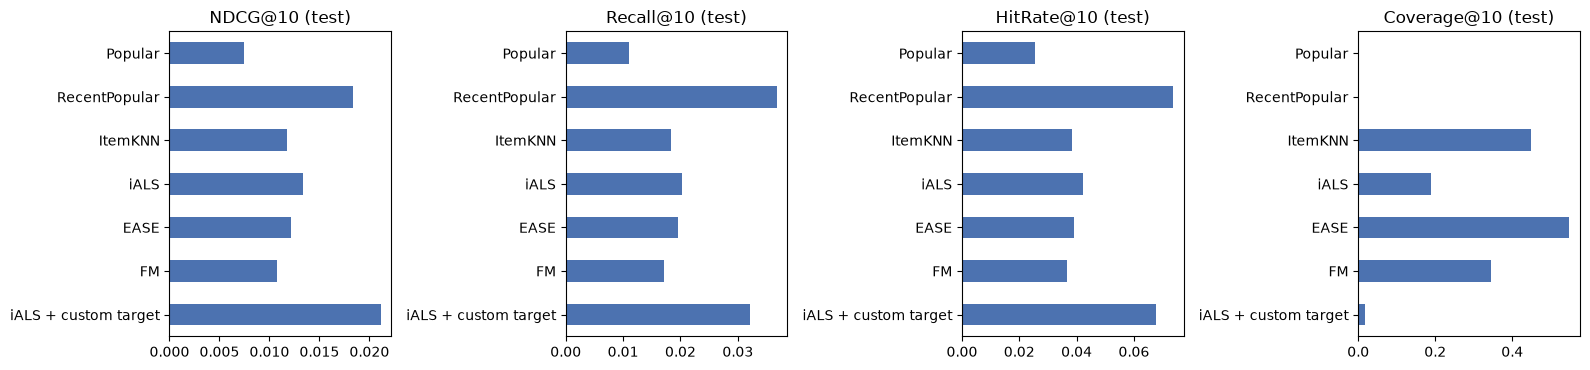

In [18]:
metrics = ["NDCG@10", "Recall@10", "HitRate@10"]
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a, mtr in zip(ax, metrics + ["Coverage@10"]):
    final[mtr].astype(float).plot.barh(ax=a, color="#4C72B0"); a.set_title(mtr + " (test)"); a.invert_yaxis()
plt.tight_layout(); plt.show()

**Статистическая значимость.** Парный бутстреп по пользователям (2000 повторов) для NDCG@10 на test: разность и 95% ДИ.

In [19]:
per_user = {n: U.ndcg_per_user(test_recs[n], test_stage.users, test_stage.rel) for n in makers}
best_model = final["NDCG@10"].astype(float).idxmax()
pairs = [(best_model, n) for n in main if n != best_model] + [
    ("FM", "FM (только ID)"), ("iALS + custom target", "RecentPopular"),
    ("абл.: g(r), r0=3", "абл.: p=1"), ("абл.: d(t)", "абл.: p=1"), ("абл.: g(r)·d(t), r0=3", "абл.: d(t)")]
pairs = list(dict.fromkeys(p for p in pairs if p[0] != p[1]))
pd.DataFrame([(a, b, *U.paired_bootstrap(per_user[a], per_user[b])) for a, b in pairs],
             columns=["A", "B", "ΔNDCG@10", "ДИ 2.5%", "ДИ 97.5%"])

,A,B,ΔNDCG@10,ДИ 2.5%,ДИ 97.5%
0,iALS + custom target,Popular,0.0137,0.0117,0.0155
1,iALS + custom target,RecentPopular,0.0027,0.0005,0.0051
2,iALS + custom target,ItemKNN,0.0094,0.0075,0.0112
3,iALS + custom target,iALS,0.0078,0.0058,0.0096
4,iALS + custom target,EASE,0.0090,0.0070,0.0109
5,iALS + custom target,FM,0.0104,0.0083,0.0124
6,FM,FM (только ID),0.0006,-0.0009,0.0022
7,"абл.: g(r), r0=3",абл.: p=1,-0.0027,-0.0042,-0.0013
8,абл.: d(t),абл.: p=1,0.0078,0.0058,0.0096
9,"абл.: g(r)·d(t), r0=3",абл.: d(t),-0.0037,-0.0053,-0.0022


### Абляции: вклад метаданных в FM и компонент кастомного таргета (test)

В абляции таргета у всех вариантов `абл.: …` одинаковые factors, λ, α (как у лучшей кастомной модели) — различается только $p_{ui}$.

In [20]:
pd.DataFrame(test_results).T.loc[["FM", "FM (только ID)", "iALS", "абл.: p=1", "абл.: g(r), r0=3", "абл.: d(t)",
                                 "абл.: g(r)·d(t), r0=3", "iALS + custom target"]]

,NDCG@10,Recall@10,HitRate@10,MRR@10,Coverage@10,"time, s"
FM,0.0108,0.0171,0.0368,0.0134,0.3459,34.5
FM (только ID),0.0101,0.0159,0.0350,0.0126,0.2909,22.8
iALS,0.0134,0.0203,0.0422,0.0170,0.1899,24.5
абл.: p=1,0.0134,0.0203,0.0422,0.0170,0.1899,24.7
"абл.: g(r), r0=3",0.0106,0.0161,0.0361,0.0135,0.1883,24.0
абл.: d(t),0.0211,0.0321,0.0677,0.0265,0.0188,24.2
"абл.: g(r)·d(t), r0=3",0.0174,0.0264,0.0554,0.0220,0.0431,24.4
iALS + custom target,0.0211,0.0321,0.0677,0.0265,0.0188,23.9


In [21]:
# пример: рекомендации для одного пользователя (история -> top-10)
titles = meta.set_index("parent_asin").title
u = test_stage.users[7]
hist = trainval[trainval.uid == u].sort_values("timestamp").tail(5)
print("Последние покупки:", [f"{titles.get(items[i], '?')[:50]} ({r:.0f}★)" for i, r in zip(hist.iid, hist.rating)])
print("Релевантные в test:", [titles.get(items[i], "?")[:50] for i in test_stage.rel[u]])
k = list(test_stage.users).index(u)
for n in ["EASE", "FM", "iALS + custom target"]:
    print(f"\n{n}:", [titles.get(items[i], "?")[:40] for i in test_recs[n][k]])

Последние покупки: ['The Walking Dead: The Telltale Series A New Fronti (1★)', 'Ghost of Tsushima - PlayStation 4 (5★)']
Релевантные в test: ['South Park: The Fractured But Whole SteelBook Gold', 'Life is Strange: True Colors - Xbox Series X']

EASE: ['The Walking Dead: Season 2 - PlayStation', 'Assassin’s Creed Valhalla Xbox Series X|', 'Mafia III - PC', "Assassin's Creed Origins - Gold Edition ", 'Dragon Quest Xi: Echoes of An Elusive Ag', 'The Last of Us Part II - PlayStation 4', 'Sekiro Shadows Die Twice - PlayStation 4', 'State of Decay: Year-One Survival Editio', 'Jurassic World Evolution - PlayStation 4', 'Nioh 2 Special Edition - PlayStation 4']

FM: ['Call of Duty: Infinite Warfare - PS4 Leg', 'Bloodborne Collectors Edition - PlayStat', 'Grand Theft Auto V: Premium Edition - Xb', 'Mass Effect Legendary - Xbox Series X [D', 'Mass Effect Andromeda Deluxe - Xbox One', 'Assassin’s Creed Valhalla Xbox Series X|', 'The Walking Dead: The Complete First Sea', 'The Wolf Among Us - Xbox

## 6. Выводы

Итог на test, основная метрика NDCG@10:

| модель | NDCG@10 | Recall@10 | HitRate@10 | Coverage@10 | гиперпараметры (по validation) |
|---|---|---|---|---|---|
| Popular | 0.0075 | 0.0110 | 0.026 | 0.2 % | — |
| RecentPopular | 0.0184 | **0.0368** | **0.074** | 0.2 % | D = 180 дней |
| ItemKNN | 0.0118 | 0.0184 | 0.039 | 44.8 % | k = 1000, shrink = 500, idf |
| iALS | 0.0134 | 0.0203 | 0.042 | 19.0 % | f = 128, λ = 500, α = 100 |
| EASE | 0.0122 | 0.0195 | 0.039 | **54.9 %** | λ = 100 |
| FM с метапризнаками | 0.0108 | 0.0171 | 0.037 | 34.6 % | f = 128, lr = 0.0026, λ = 0.01, 12 эпох |
| **iALS + свой таргет** | **0.0211** | 0.0321 | 0.068 | 1.9 % | f = 128, λ = 500, α = 100, r0 = None, h = 365 дн., γ = 0.2 |

1. **Лучше всех по NDCG@10 — iALS со своим таргетом**: 0.0211 против 0.0134 у обычного iALS (+57 %, 95 % ДИ разности
   [0.006; 0.010]). Остальные модели он тоже обходит значимо. В абляции я оставил factors, λ, α одинаковыми и менял
   только $p_{ui}$: переход от $p_{ui}=1$ к $p_{ui}=d(t)$ даёт +0.0078 NDCG@10 (ДИ [0.0058; 0.0096]).
2. **Работает только временная часть, а учёт оценки мешает.** На validation лучшей оказалась конфигурация без
   $g(r)$ ($r_0$ = None), и на test это подтвердилось: $g(r)$ с $r_0=3$ ухудшает и обычный iALS (−0.0027), и вариант
   с затуханием (−0.0037), оба эффекта значимы. Я думаю, дело в том, что покупка с плохой оценкой всё равно говорит
   об интересе к платформе или жанру (часто единицы ставят за доставку, комплектацию или DLC), а отрицательный
   таргет отталкивает пользователя от целого кластера похожих товаров. Затухание с полураспадом в год помогает,
   потому что игры — очень «временной» рынок: покупают новые релизы и под текущее поколение консолей.
3. **Популярность сильно меняется со временем.** Популярность за последние 180 дней обгоняет все классические
   персональные модели, которые учились на всей истории 2015–2021, а по Recall@10 и HitRate@10 она лучше даже моего
   iALS. По NDCG@10 и MRR@10 iALS со своим таргетом всё же выигрывает (+0.0027, ДИ [0.0005; 0.0051]), то есть ставит
   нужное выше. Минус — очень узкая выдача (покрытие каталога 1.9 %): модель в основном персонализирует среди
   актуальных товаров.
4. **Классические модели** (ItemKNN, iALS, EASE) почти не отличаются: NDCG 0.012–0.013. На validation лучшим был EASE,
   на test — iALS, но разница в пределах шума. Зато EASE и ItemKNN рекомендуют гораздо больше разных товаров
   (45–55 % каталога).
5. **Метаданные в FM** дают небольшой плюс к FM только на ID (NDCG +0.0006, Recall 0.0171 против 0.0159, покрытие 35 %
   против 29 %), но он статистически незначим (ДИ [−0.0009; 0.0022]). Видимо, у тёплых пользователей с историей
   ID-эмбеддинги и так знают почти всё, а метаданные сильнее помогли бы на новых товарах, которые я не оцениваю.
   FM с BPR и случайными негативами вообще уступила iALS и EASE.

**Ограничения.**
* Абсолютные метрики маленькие: данные очень разреженные (0.1 %), у пользователя в медиане 6 покупок, отложенный
  период длится год и больше, а ~25 % хороших покупок в test (19 % в validation) — товары, которых не было в
  обучении, их не может порекомендовать ни одна модель.
* Видим не все покупки, а только те, к которым оставили отзыв; релевантность считаю по оценке ≥ 4.
* Фильтр по числу взаимодействий я делал на всём периоде до разбиения. Так обычно делают, но это небольшая утечка
  при отборе пользователей и товаров. Оцениваются только пользователи с историей.
* Гиперпараметры подбирал на одном временном срезе (2021). У ItemKNN и iALS лучшие значения лежат на краю сетки, но
  там уже плато: соседние конфигурации отличаются на ~0.0001 NDCG. Таргет подбирал при factors от лучшего iALS.
* Что можно попробовать дальше: добавить затухание по времени в EASE и ItemKNN (взвешивать строки матрицы) и
  использовать метапризнаки FM для новых товаров.
